# DADA3: 1 - The fixer and the verifier

Five TODOs, 8 points.

This notebook builds the two agents that work on one issue, and the handoff between them. The fixer reads the code and writes a fix, but it cannot run anything. The verifier is a deep agent with a sandbox: it writes its own test from the issue, runs it before and after the fix, and either accepts the fix or sends it back to the fixer with the failing output. 

Notebook 02 runs one such pair for every bug, in parallel.

The bottom half of the diagram is what you will build in this notebook.

![architecture](figures/architecture.png)

In [1]:
from dotenv import load_dotenv
load_dotenv()

import importlib
from bugteam import config, repo

files = repo.repo_files()
issues = {i["number"]: i for i in repo.load_issues()}
print(config.CHAT_BACKEND, config.model_name(), "| sandbox:", config.SANDBOX)

gemini gemini-3.5-flash-lite | sandbox: daytona


## 1. The fixer's tools

The fixer has three tools. `list_files` is given. You'll write the other two tools.

- `read_file(path)` returns one file of the repository. When the path is wrong, it should say so and list the files, so that the model can correct itself, as the tools in W03b did when an order id was wrong.
- `transfer_to_verifier(path, new_code, note)` is the handoff. It plays the part of `transfer_to_returns` in W08a: calling it says "my part is done, the verifier works next". Its arguments carry the work over: the file the fixer changed, the complete new content of that file, and a note for the verifier and for the report.

When the fixer calls `transfer_to_verifier`, its part is done. The graph you write in TODO 1.2 stops it there, the way `after_tools` stopped an agent after a handoff in W08a.

### TODO 1.1: the fixer's tools (2 pts)

`bugteam/fixer.py`: `read_file` and `transfer_to_verifier`.

**Steps:**

1. `read_file(path)`: get the files with `repo_files()`. If `path` is not one of them, return a message that says there is no such file and lists the files, one per line. Otherwise return the file's text.
2. `transfer_to_verifier(path, new_code, note)`: return `"The verifier has your fix."`. The tool does not store the fix anywhere: the fix is in the arguments of the tool call, and `find_fix` reads it from there.

Keep the docstrings. The model reads them to decide when to call each tool.

In [2]:
from langchain.tools import tool
from bugteam.fixer import list_files
from bugteam.repo import repo_files


# TODO 1.1
@tool
def read_file(path: str) -> str:
    """Read one file of the repository, for example huskyutils/text.py."""
    files = repo_files()
    if path not in files:
        return f"There is no file {path!r}. The files are:\n" + "\n".join(files)
    return files[path]


@tool
def transfer_to_verifier(path: str, new_code: str, note: str) -> str:
    """Hand your fix to the verifier. path: the file you changed. new_code: the complete new content of
    that file. note: what was wrong and what you changed, in one or two sentences."""
    return "The verifier has your fix."

In [3]:
assert "def slugify" in read_file.invoke({"path": "huskyutils/text.py"})
assert "huskyutils/text.py" in read_file.invoke({"path": "text.py"}), "a wrong path should list the files"
assert transfer_to_verifier.invoke({"path": "huskyutils/text.py", "new_code": "x = 1", "note": "n"}) == "The verifier has your fix."
print("the tools work")

the tools work


## 2. The fixer's loop

The fixer is the same ReAct loop you have built since W04b: an `assistant` node that calls the model with the tools bound, a `ToolNode`, and `tools_condition` between them. The one change is the one from W08a's swarm: after a handoff tool runs, the agent must stop instead of going back to the model, so that the graph around it can decide who works next.

After the `tools` node runs, the last message in the state is the `ToolMessage` with the tool's result, and its `name` is the name of the tool that ran. If the name is `transfer_to_verifier`, the fix was handed over. This is the check from `after_tools` in W08a.

### TODO 1.2: stop after the handoff (1 pt)

`bugteam/fixer.py`: `after_tools`.

**Steps:**

1. Read the last message in `state["messages"]`.
2. Return `END` if its `name` is `"transfer_to_verifier"`, and `"assistant"` otherwise.

`build_fixer` below is given. Read where `after_tools` is used in it.

In [4]:
from langchain.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from bugteam.fixer import FIXER_PROMPT, find_fix
from bugteam.util import retry

TOOLS = [list_files, read_file, transfer_to_verifier]


# TODO 1.2
def after_tools(state: MessagesState) -> str:
    return END if state["messages"][-1].name == "transfer_to_verifier" else "assistant"


def build_fixer():
    model_with_tools = config.chat().bind_tools(TOOLS)
    sys_msg = SystemMessage(content=FIXER_PROMPT)

    def assistant(state: MessagesState) -> dict:
        return {"messages": [retry(model_with_tools.invoke, [sys_msg] + state["messages"])]}

    builder = StateGraph(MessagesState)
    builder.add_node("assistant", assistant)
    builder.add_node("tools", ToolNode(TOOLS))
    builder.add_edge(START, "assistant")
    builder.add_conditional_edges("assistant", tools_condition)
    builder.add_conditional_edges("tools", after_tools, ["assistant", END])
    return builder.compile()

Run the fixer on issue #6, the shipping price for a 1 kg package. `show` prints each message: the model's tool calls, and the first line of what each tool returned. `find_fix` (given, in `fixer.py`) reads the fix from the arguments of the `transfer_to_verifier` call, and `repo.diff` prints it the way a pull request shows a change.

In [5]:
from langchain.messages import HumanMessage
from bugteam.util import text_of


def show(messages):
    for m in messages:
        calls = [f"{c['name']}({', '.join(c['args'])})" for c in getattr(m, "tool_calls", None) or []]
        text = text_of(m).strip().split("\n")[0][:100]
        print(f"{m.type:6} {text!r} {calls or ''}")


print(FIXER_PROMPT)
print()

out = build_fixer().invoke({"messages": [HumanMessage(content=repo.issue_text(issues[6]))]})
show(out["messages"])



You fix one bug in huskyutils, a small Python library. You can read the repository's
files, but you cannot run code. Another agent, the verifier, runs your fix in a sandbox.

- Read the files the issue is about with read_file. The function's docstring is its specification:
  when the code and the docstring disagree, change the code to match the docstring.
- Change as little as you can, and only one file. Do not change the tests or the docstring.
- When the fix is ready, call transfer_to_verifier with the path of the file, its complete new
  content, and a note that says what was wrong and what you changed.
- If the verifier sends the fix back, read its reason and the failing output, correct the fix,
  and call transfer_to_verifier again.

human  'Issue #6: A 1 kg package is charged $9 shipping' 
ai     '' ['list_files()']
tool   'README.md' 
ai     '' ['read_file(path)']
tool   '"""Shipping prices."""' 
ai     '' ['transfer_to_verifier(note, new_code, path)']
tool   'The verifier has y

In [6]:
fix6 = find_fix(out["messages"])
print("\nnote:", fix6["note"])
print(repo.diff(fix6["path"], files[fix6["path"]], fix6["new_code"]))


note: Changed weight_kg < 1 to weight_kg <= 1 so that packages weighing exactly 1 kg are charged $5.00 as per the docstring.
--- a/huskyutils/shipping.py
+++ b/huskyutils/shipping.py
@@ -12,7 +12,7 @@
         shipping_cost(0.4) == 500
         shipping_cost(5.2) == 1100
     """
-    if weight_kg < 1:
+    if weight_kg <= 1:
         return 500
     if weight_kg <= 5:
         return 900



Read the diff. Is it the change the docstring asks for? The fixer has not run it, and it cannot. That is the verifier's job.

## 3. The verifier

The verifier is a deep agent, built with `create_deep_agent` as in W09a.2, and its backend is a sandbox, as in W09b.2. Each time it runs, `verify` makes a new sandbox with two copies of the repository:

- `original/`, the repository before the fix
- `fixed/`, the repository with the fixer's new file in place

The verifier reads the issue and the docstring, writes a test of its own in `tests/test_issue.py`, and runs the tests in both folders. A good test fails in `original/`, which shows that it reproduces the issue, and passes in `fixed/`, along with every test that was already there.

The verifier is told which file changed, but it is not shown the change. If it saw the fixer's code, it would be tempted to write a test that the code passes, rather than a test of what the docstring promises. 

This is the reason for having two agents at all: a check is more useful when it is made by an agent that did not write what it is checking.

Read the prompt:

In [7]:
from bugteam.verifier import VERIFIER_PROMPT

print(VERIFIER_PROMPT.format(workdir="/home/daytona"))

You check a proposed fix for one issue in huskyutils, a small Python library.
Another agent wrote the fix. You are not shown the change, so that your tests come from the issue
and the docstring and not from the fix. Your files are under /home/daytona:

- /home/daytona/original/ is the repository before the fix
- /home/daytona/fixed/ is the repository with the fix

Run Python with execute. The tests use unittest. To run them, cd into one of the two folders and run
`python -m unittest discover -s tests -v`.

1. Read the issue, and the docstring of the function it is about. The docstring is the specification.
2. Write tests/test_issue.py in both folders. It checks what the issue and the docstring say the
   function should do, including every example in the docstring. Write it from the issue and the
   docstring, not from the fix. Test only inputs the docstring allows: if it says a value is at
   least 1, do not test 0.
3. Run all the tests in both folders. Your test should fail in origin

The verifier ends its run by calling one of two handoff tools: `accept_fix(evidence)`, or `transfer_to_fixer(reason)` with the failing test and its output. The reason is what the fixer reads next, so it has to say what is wrong.

In TODO 1.2 you stopped the fixer after its handoff by adding a conditional edge. A deep agent's loop is built by the library, so we cannot add an edge to it. LangChain has another way to do the same thing: a tool declared with `@tool(return_direct=True)` ends the agent's run as soon as it has been called, and its result becomes the last message.

`decision(messages)` then reads which of the two the verifier called, from the tool calls in its messages, which is how `find_fix` reads the fixer's.

### TODO 1.3: the verifier's handoffs (2 pts)

`bugteam/verifier.py`: `accept_fix`, `transfer_to_fixer`, and `decision`.

**Steps:**

1. Declare both tools with `@tool(return_direct=True)`. `accept_fix(evidence: str)` returns `"Fix accepted."` and `transfer_to_fixer(reason: str)` returns `"Sent back to the fixer."`. 
    - Keep the docstrings below; the model reads them.


2. `decision(messages)`: go through the messages from the last to the first. For each message, look at its `tool_calls` (a message without them has none: use `getattr(m, "tool_calls", None) or []`). Return `("accept", call["args"]["evidence"])` for the first `accept_fix` call you find, and `("reject", call["args"]["reason"])` for the first `transfer_to_fixer` call. If there is neither, return `("none", "")`: the verifier stopped without deciding.

In [8]:
# TODO 1.3
@tool(return_direct=True)
def accept_fix(evidence: str) -> str:
    """Accept the fix. evidence: the commands you ran and what they showed, briefly."""
    return "Fix accepted."


@tool(return_direct=True)
def transfer_to_fixer(reason: str) -> str:
    """Send the fix back to the fixer. reason: what is wrong, with the failing test and its output."""
    return "Sent back to the fixer."


def decision(messages):
    for m in reversed(messages):
        for call in getattr(m, "tool_calls", None) or []:
            if call["name"] == "accept_fix":
                return ("accept", call["args"].get("evidence", ""))
            if call["name"] == "transfer_to_fixer":
                return ("reject", call["args"].get("reason", ""))
    return ("none", "")

Run the following cell to test your handoffs:

In [9]:
from langchain.messages import AIMessage

ran = AIMessage(content="", tool_calls=[{"name": "execute", "args": {"command": "ls"}, "id": "1"}])
sent_back = AIMessage(content="", tool_calls=[{"name": "transfer_to_fixer", "args": {"reason": "test fails"}, "id": "2"}])
accepted = AIMessage(content="", tool_calls=[{"name": "accept_fix", "args": {"evidence": "all pass"}, "id": "3"}])

assert accept_fix.return_direct and transfer_to_fixer.return_direct, "both tools must end the run"
assert decision([ran, sent_back]) == ("reject", "test fails")
assert decision([ran, sent_back, accepted]) == ("accept", "all pass"), "the last decision counts"
assert decision([ran]) == ("none", "")
print("the handoffs work")

the handoffs work


### TODO 1.4: one verification (2 pts)

`bugteam/verifier.py`: `verify(issue, fix)`.

`verify` runs the verifier once on one fix, in a new sandbox, and returns `{"decision": ..., "message": ..., "test": ...}`. 

`fix` is the dictionary of arguments the fixer passed to `transfer_to_verifier`: `path`, `new_code`, and `note`.

**Steps:**

1. Get the files with `repo_files()`, and make `fixed`, a copy of that dictionary with `fix["path"]` replaced by `fix["new_code"]`.
2. Open a sandbox with `with open_sandbox() as (sandbox, workdir):`. Inside the block, upload `files` to `f"{workdir}/original"` and `fixed` to `f"{workdir}/fixed"`.
3. Make the deep agent with VERIFIER prompt and the two tools (`accept_fix` and `transfer_to_fixer`). Use the sandbox as its backend.
4. The request is the issue's text, `issue_text(issue)`, followed by one sentence naming the file the fixer changed. Do not include the change.
5. Invoke the agent with the request as a `HumanMessage` and `{"recursion_limit": 80}`. A verifier that keeps running commands without deciding reaches that limit, and LangGraph raises `GraphRecursionError`; catch it, and treat it as `("none", "The verifier ran out of steps before it accepted or rejected the fix.")`. Otherwise get the decision with `decision(out["messages"])`.
6. Still inside the `with` block, before the sandbox is deleted, read the test the verifier wrote: `read_sandbox_file(sandbox, f"{workdir}/fixed/tests/test_issue.py")`. It is `""` if there is none.
7. Return the dictionary.

In [10]:
from deepagents import create_deep_agent
from langgraph.errors import GraphRecursionError
from bugteam.repo import issue_text
from bugteam.sandbox import open_sandbox, read_sandbox_file, upload_files


# TODO 1.4
def verify(issue, fix):
    files = repo_files()
    fixed = {**files, fix["path"]: fix["new_code"]}
    with open_sandbox() as (sandbox, workdir):
        upload_files(sandbox, files, f"{workdir}/original")
        upload_files(sandbox, fixed, f"{workdir}/fixed")
        agent = create_deep_agent(model=config.chat(), tools=[accept_fix, transfer_to_fixer],
                                  system_prompt=VERIFIER_PROMPT.format(workdir=workdir), backend=sandbox)
        request = issue_text(issue) + f"\n\nThe fixer changed {fix['path']}."
        try:
            out = agent.invoke({"messages": [HumanMessage(content=request)]}, {"recursion_limit": 80})
            verdict, message = decision(out["messages"])
        except GraphRecursionError:
            verdict, message = "none", "The verifier ran out of steps before it accepted or rejected the fix."
        test = read_sandbox_file(sandbox, f"{workdir}/fixed/tests/test_issue.py")
    return {"decision": verdict, "message": message, "test": test}

Verify the fixer's fix for #6. This makes a sandbox and runs the deep agent, so it takes half a minute or so.

In [11]:
result6 = verify(issues[6], fix6)
print("decision:", result6["decision"])
print("message: ", result6["message"])
print()
print(result6["test"])

Sandbox glob could not read 6 path(s) under '/'; results are incomplete. Sample: ['PermissionError:./etc/credstore', 'PermissionError:./etc/credstore.encrypted', 'PermissionError:./etc/polkit-1/rules.d', 'PermissionError:./etc/ssl/private', 'PermissionError:./home/vscode']


decision: accept
message:  Ran `cd /home/daytona/original && python -m unittest discover -s tests -v`, which failed on `test_up_to_and_including_1_kg` with `AssertionError: 900 != 500`. Ran `cd /home/daytona/fixed && python -m unittest discover -s tests -v`, which successfully ran all 27 tests including our new test and all existing tests.

import unittest

from huskyutils.shipping import shipping_cost


class TestIssueShipping(unittest.TestCase):
    def test_docstring_examples(self):
        self.assertEqual(shipping_cost(0.4), 500)
        self.assertEqual(shipping_cost(5.2), 1100)

    def test_up_to_and_including_1_kg(self):
        self.assertEqual(shipping_cost(1), 500)



Read the test the verifier wrote, not only its decision.

- Does it check the case in the issue, a 1 kg package?
- Does it check the boundaries the docstring names: exactly 1 kg, just over 1 kg, exactly 5 kg, just over 5 kg?
- Would it fail on the original code? If you are not sure, the message should say what it saw in `original/`.

A verifier that accepts a fix on a weak test is worse than no verifier, because its "verified" is believed. Notebook 03 measures how often that happens.

## Move your code into the modules

The pair in the next section is built from the two nodes in `bugteam/pair.py`, and they call the module's `build_fixer` and `verify`. So move your code there now:

- `read_file`, `transfer_to_verifier`, and `after_tools` into `bugteam/fixer.py`
- `accept_fix`, `transfer_to_fixer`, `decision`, and `verify` into `bugteam/verifier.py`

Then run the cell below. It makes no model calls.

In [12]:
from langchain.messages import ToolMessage
from bugteam import fixer, pair, verifier
for module in (fixer, verifier, pair):
    importlib.reload(module)

handed = ToolMessage(content="The verifier has your fix.", name="transfer_to_verifier", tool_call_id="1")
assert "def slugify" in fixer.read_file.invoke({"path": "huskyutils/text.py"})
assert fixer.after_tools({"messages": [handed]}) == END
assert verifier.accept_fix.return_direct and verifier.transfer_to_fixer.return_direct
assert verifier.decision([ran, sent_back]) == ("reject", "test fails")
print("fixer.py and verifier.py work")

fixer.py and verifier.py work


## 4. The pair

`bugteam/pair.py` puts the two agents in one graph. Its state, `PairState`, keeps the fixer's conversation across rounds, the last fix, how many times the verifier has run, and a log of the handoffs.

```
START -> fixer --transfer_to_verifier--> verifier --accept_fix--> END
           ^                                |
           +-------transfer_to_fixer--------+      at most MAX_ROUNDS verifier runs
```

The two nodes are given. Read them in `pair.py`.

- `fixer_node` runs the fixer on its conversation so far, and reads the fix with `find_fix`. If the fixer stopped without handing a fix over, it sets `status` to `"no_fix"`.
- `verifier_node` runs `verify`. If the verifier accepted, `status` becomes `"verified"`. If not, `status` becomes `"rejected"`, and the verifier's reason is added to the fixer's conversation as a new message. That message is the handoff: it is how the failing test reaches the fixer.

Both nodes call the module's `build_fixer` and `verify`, which now hold your code.

### TODO 1.5: who works next (1 pt)

`bugteam/pair.py`: `after_fixer` and `after_verifier`.

**Steps:**

1. `after_fixer(state)`: return `END` if `state["status"]` is `"no_fix"`, and `"verifier"` otherwise.
2. `after_verifier(state)`: return `END` if the fix was verified, or if `state["rounds"]` has reached `config.MAX_ROUNDS`. Otherwise return `"fixer"`.

In [13]:
from bugteam.pair import PairState


# TODO 1.5
def after_fixer(state: PairState) -> str:
    return END if state["status"] == "no_fix" else "verifier"


def after_verifier(state: PairState) -> str:
    if state["status"] == "verified" or state["rounds"] >= config.MAX_ROUNDS:
        return END
    return "fixer"

In [14]:
assert after_fixer({"status": "no_fix"}) == END
assert after_fixer({"status": "checking"}) == "verifier"
assert after_verifier({"status": "verified", "rounds": 1}) == END
assert after_verifier({"status": "rejected", "rounds": 1}) == "fixer"
assert after_verifier({"status": "rejected", "rounds": config.MAX_ROUNDS}) == END, "the rounds are used up"
print("the routing works")

the routing works


Now the pair, built here with your functions. `run_pair` gives it the issue and prints the log of handoffs. Run it on #1, the slugs with double hyphens. Read the docstring of `slugify` again first: it promises something the issue does not mention.

In [15]:
builder = StateGraph(PairState)
builder.add_node("fixer", pair.fixer_node)
builder.add_node("verifier", pair.verifier_node)
builder.add_edge(START, "fixer")
builder.add_conditional_edges("fixer", after_fixer, ["verifier", END])
builder.add_conditional_edges("verifier", after_verifier, ["fixer", END])
pair_here = builder.compile()

Take a look at the graph:

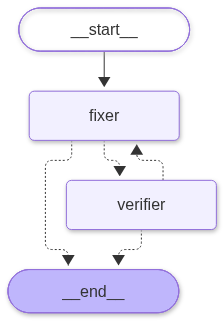

In [16]:
from IPython.display import Image, display
display(Image(pair_here.get_graph().draw_mermaid_png()))

In [17]:
def run_pair(issue):
    out = pair_here.invoke({"issue": issue, "messages": [HumanMessage(content=repo.issue_text(issue))]},
                           {"recursion_limit": 40})
    print(f"#{issue['number']}: {out['status']} after {out['rounds']} verifier run(s)\n")
    for line in out["log"]:
        print("-", line, "\n")
    return out


pair1 = run_pair(issues[1])

Sandbox glob could not read 6 path(s) under '/'; results are incomplete. Sample: ['PermissionError:./etc/credstore', 'PermissionError:./etc/credstore.encrypted', 'PermissionError:./etc/polkit-1/rules.d', 'PermissionError:./etc/ssl/private', 'PermissionError:./home/vscode']


#1: verified after 1 verifier run(s)

- fixer -> verifier: Fixed slugify to handle accents, multiple non-alphanumeric characters collapsing into single hyphens, and stripping leading/trailing hyphens as specified in the docstring. 

- verifier accepted the fix 



Read the log.

- Did the verifier send the fix back? If it did, was its reason right: does the fix the fixer first wrote really fail what the docstring says? Did the second fix address the reason?
- If it accepted the first fix, print `pair1["test"]` and check whether the test covers every example in the docstring, including the accented title.

Run the pair on #2 as well, the payment split. The reporter suggests a fix there. Is it the fix the docstring asks for?

In [18]:
pair2 = run_pair(issues[2])

#2: verified after 2 verifier run(s)

- fixer -> verifier: Updated split_amount to correctly distribute remainder cents among the first shares according to the docstring. 

- verifier -> fixer: The fixed implementation of split_amount returns [-333, -333, -334] for split_amount(-1000, 3) because it applies the remainder to the beginning of the list (`shares[i] -= 1` for i in range(abs(remainder))), whereas negative integer division in Python (e.g. -1000 // 3 = -334) leaves a positive remainder or different remainder behavior, or the docstring specifies `split_amount(-1000, 3) == [-334, -333, -333]`. 

- fixer -> verifier: Fixed split_amount to correctly compute base and remainder using absolute values, ensuring negative amounts place the extra absolute cent on the first shares (resulting in more negative first shares) per docstring. 

- verifier accepted the fix 



## Before you move on

Move `after_fixer` and `after_verifier` into `bugteam/pair.py`. Notebook 02 imports the pair from there.

Then run the cell below. It runs the module's pair on #8.

In [19]:
importlib.reload(pair)

record = pair.fix_issue(issues[8])
assert set(record) >= {"number", "status", "rounds", "fix", "evidence", "test", "log"}
print(record["status"], "after", record["rounds"], "verifier run(s)")
for line in record["log"]:
    print("-", line[:300])

Sandbox glob could not read 6 path(s) under '/'; results are incomplete. Sample: ['PermissionError:./etc/credstore', 'PermissionError:./etc/credstore.encrypted', 'PermissionError:./etc/polkit-1/rules.d', 'PermissionError:./etc/ssl/private', 'PermissionError:./home/vscode']


verified after 1 verifier run(s)
- fixer -> verifier: Fixed median calculation for an even number of values to return the average of the two middle values as specified in the docstring.
- verifier accepted the fix
